In [169]:
#Churn bhaneko chai "Leave garnu" ho 
#Customer Churn bhaneko chai "Kunai pani Company bata Customer le Leave garnu" ho
#so Customer Churn Prediction ko kaam bhaneko chai "Kunai pani Company ko Customer le Leave garne ho ki nai" bhanne kura predict garnu ho

#so that Company le chai Agadinai tyo Customer lai Discount , Offer haru dina sakcha 

#Business Goal : Reduce Churn 

In [170]:
#since yo Classification Problem ho so hamile Classification Algorithm haru use garna parcha
#specially yo Binary Classification Problem ho because esma Either Churn=Yes or Churn=No huncha

#there are many Classification Algorithm haru like Logistic Regression, Decision Tree, Random Forest, Support Vector Machine, Naive Bayes, K-Nearest Neighbors etc.

#so Each Model Compare ni garne kun le chai Ramro Output dincha 

## Task 1 : Understanding the Problem

In [171]:
#At First Data Cleaning garne

In [172]:
import pandas as pd 

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

#yo Dataset bhaneko chai Telco Company ko Customer Churn ko Data ho

#Dataset 3 Parts ma Divide chan

#1. Demographic Information : Customer ko Personal Information
#2. Services Information : Customer le kun kun Service haru use gariraheko cha

#esle Provide gareko Services haru chai PhoneService , MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies etc. haru ho

#3. Account Information : Customer ko Account ko Information haru jastai ki Tenure, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges etc.

df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [173]:

df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [174]:
"""

** Logic **

-> customerID ko kunai pani Role chaina Machine Learning Model ma so we can drop that column

=> Demographic Columns : 

a. gender -> yo pani strong Feature haina for ML Model so we can drop that column

b. SeniorCitizen -> yo chai Less Important huna sakcha for ML Model 
because Older People haru le chai Churn garne Chance thulo huncha 
as They need Support more and Tech Issue huda leave garne Chance thulo huncha

c. Partner -> yo chai Customer married or not bhanne kura ho
Family bhaeko people haru chai generally Stable hunchan and Churn garne chance Low huncha

d. Dependents -> yo chai Customer sanga dependent Family Members chaki chaina like Parents , Children
yo pani Dependents bhaeka User haru le chai Stable Plan choose garna sakchan and Service continue garna sakchan so Churn garne Chance Low huncha


=> Services Columns :

a. PhoneService -> yo chai Customer le Phone Service use gariraheko cha ki chaina bhanne kura ho


b. MultipleLines -> yo chai Customer le Multiple Lines use gariraheko cha ki chaina bhanne kura ho


c. InternetService -> yo chai Customer le Internet Service use gariraheko cha ki chaina bhanne kura ho

--> yo chai Important Feature huna sakcha because 
Internet Service use gariraheko Customer haru le chai Tech Issue huda leave garne Chance thulo huncha

yo alik Badi Important Feature ho Because 
Internet Quality directly affects Satisfacation 
Example : Slow internet , Expensive Fiber , No Internet huda Churn garne chance High huncha

-> Fiber Optic Users haru chai Sometimes Churn garne Chance badi huncha as yo Expensive huncha and Expectations pani High huncha that Fast Internet huncha bhanera


d. OnlineSecurity -> yo chai Customer le Online Security Service use gariraheko cha ki chaina bhanne kura ho

--> yo chai Important Feature huna sakcha because Online Security Service use gariraheko Customer haru Invested Customers , Company sanga Attached hunchan so 
they are Less Likely to Churn


c. OnlineBackup -> yo chai Customer le Online Backup Service use gariraheko cha ki chaina bhanne kura ho

d. DeviceProtection -> yo chai Customer le Device Protection Service use gariraheko cha ki chaina bhanne kura ho


e. TechSupport -> yo chai Customer le Tech Support Service use gariraheko cha ki chaina bhanne kura ho
--> yo Important Feature ho because
No Support : Fustration to User
Support Available : Happy Customer 
so Tech Support bhaeko Customer haru generally Less Churn

f. StreamingTV -> yo chai Customer le Entertainment Services use gariraheko cha ki chaina bhanne kura ho

--> yo Important Feature ho because
Customer le More Services use gareko cha bhane More Dependent on Company so Less likely to Churn



=> Account Information :

a. Tenure -> yo chai Customer le Company sanga kati Months dekhi connected cha bhanne kura ho

--> yo Important Feature ho because
New Customers or Lesser time Tenure bhaeko Customers haru le Churn garne Chance high Huncha
whereas Longer Tenure bhaeko Customers haru le Churn garne Chance Low Huncha


b. Contract -> yo chai Customer le kun Contract Type choose gareko cha bhanne kura ho

-> yo Extremelyt Important Feature ho because
Generally Longer Contract choose gareko Customers haru le Churn garne Chance Low Huncha
Example : month-to-month contract choose gareko Customers haru le Churn garne Chance High Huncha
whereas Two year Contract choose gareko Customers haru le Churn garne Chance Low Huncha


c. PaperlessBilling -> yo chai Customer Online Billing use garcha ki Paper billing use garcha bhanne kura ho


d. PaymentMethod -> yo chai Customer le kun Payment Method use gariraheko cha bhanne kura ho

--> yo Important Feature ho because 
Generally Credit Card use gariraheko Customers haru le Churn garne Chance Low Huncha because Credit Card use gariraheko Customers haru le Automatic Payment Setup gareko huncha so they are Less Likely to Churn
whereas Customers who use Electronic Check le Churn garne Chance High Huncha because they have to manually pay every month so they are More Likely to Churn


e. MonthlyCharges -> yo chai Customer le Monthly Kati Paisa pay gariraheko cha bhanne kura ho

--> yo Important Feature ho because
Generally Jati Badi Paisa pay gariraheko cha bhane Churn garne Chance High Huncha because they have to pay more so they are More Likely to Churn

so High Bills = dissatisfaction = Churn


f. TotalCharges -> yo chai Customer le Total money kati Pay gareko cha till now.

-> yo Important Feature ho because
High TotalCharges pay gareko Customer haru Long Term stay gareko huncha so 
Long Stay means Less Churn Chance

TotalCharges = MonthlyCharges * Tenure


==> Churn -> yo chai Target Column ho jasma Yes or No value cha
-> yo chai Final thing to Predict 



#Summary :

Tenure , InternetSevice , OnlineSecurity , TechSupport, Contract , PaymentMethod , MonthlyCharges, TotalCharges are Important Features for ML Model

but SeniorCitizen , Partner , Dependents , PhoneService , MultipleLines , OnlineBackup , DeviceProtection , StreamingMovies are Less Important Features for ML Model

CustomerID and Gender are not Important for ML Model so we can drop those columns

"""

'\n\n** Logic **\n\n-> customerID ko kunai pani Role chaina Machine Learning Model ma so we can drop that column\n\n=> Demographic Columns : \n\na. gender -> yo pani strong Feature haina for ML Model so we can drop that column\n\nb. SeniorCitizen -> yo chai Less Important huna sakcha for ML Model \nbecause Older People haru le chai Churn garne Chance thulo huncha \nas They need Support more and Tech Issue huda leave garne Chance thulo huncha\n\nc. Partner -> yo chai Customer married or not bhanne kura ho\nFamily bhaeko people haru chai generally Stable hunchan and Churn garne chance Low huncha\n\nd. Dependents -> yo chai Customer sanga dependent Family Members chaki chaina like Parents , Children\nyo pani Dependents bhaeka User haru le chai Stable Plan choose garna sakchan and Service continue garna sakchan so Churn garne Chance Low huncha\n\n\n=> Services Columns :\n\na. PhoneService -> yo chai Customer le Phone Service use gariraheko cha ki chaina bhanne kura ho\n\n\nb. MultipleLines

In [175]:
df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

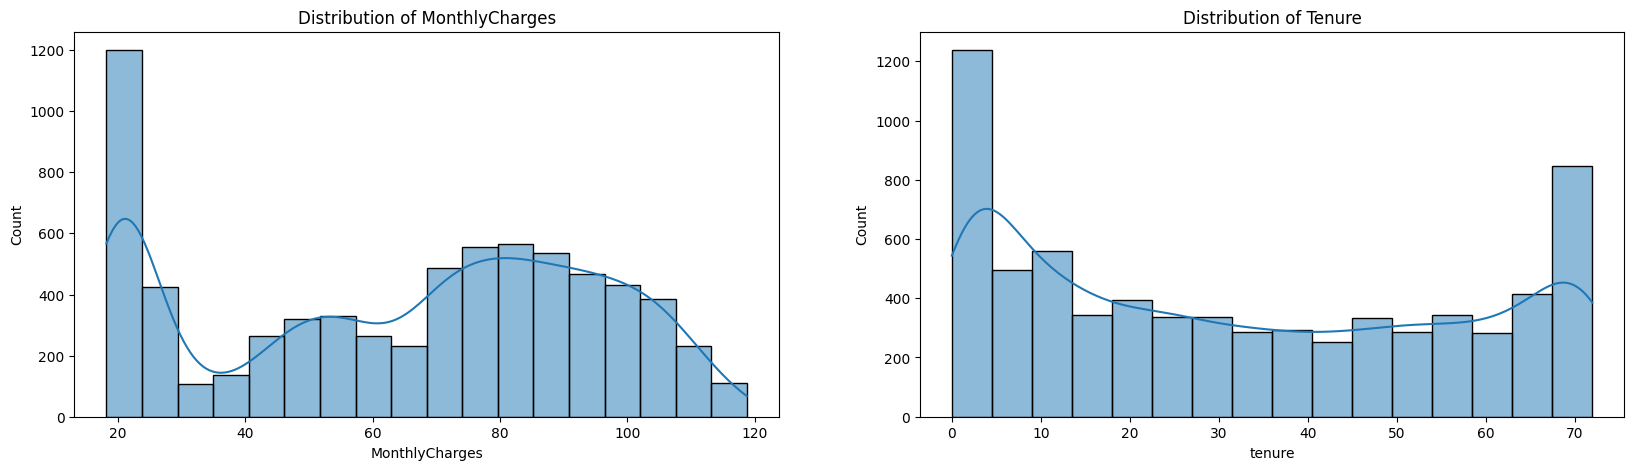

'Tenure Curve Analysis '

In [176]:
#Task1 :

"""  
#Problem Type : 
-> Supervised Learning ho and Specially Binary Classification Problem ho because Target Column Churn ma Yes or No value cha


#Target Variable 
-> Churn (Yes or No) so esle chai Bernoulli Distribution follow garne ho


#Loss Function
-> Binary Classification lai chai Binary Cross Entropy Loss Function use garda better ho 


#Assumptions

1. Each customer chai Independent cha 

if violated then Model learns wrong patterns 

2. Past behavior chai Future behavior ko Indicator ho
like tenure , charges --> future churn 

if violated then Model becomes useless for prediction

3. Data is Representative 
which means Dataset le chai Real Customers represent gareko cha

if violated then Model fails to generalize to real-world scenarios



#Uncertainty in Dataset (Noise , Bias , Missing)

1. TotalCharges Column ma chai 11 ota Empty Values chan having Whitespace Strings ("") which is Noise in Dataset

2. Dataset is Imbalanced: approximately 27% of customers churned. This affects model training, metric choice, and threshold decisions which is Bias in Dataset


"""

#Distribution Analysis of MonthlyCharges , tenure and TotalCharges

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(20,5))

plt.subplot(1,2,1)
sns.histplot(df["MonthlyCharges"], kde=True)
plt.title("Distribution of MonthlyCharges")

plt.subplot(1,2,2)
sns.histplot(df["tenure"], kde=True)
plt.title("Distribution of Tenure")

plt.show()

"""Monthly Charges Curve Analysis"""

#MonthlyCharges ko KDE Curve chai "BiModal" Cha which means Euta Peak chai around 20-30 ko cha and Arko Peak chai around 70-90 ko cha which means Customer haru generally 2 Category ma parcha

#1. Low Monthly Charges pay gariraheko cha (20-30) which means they are using basic services and they are generally satisfied with the service so they are less likely to churn

#2. High Monthly Charges pay gariraheko cha (70-90) which means they are using more services and can be premium customers but they are more likely to churn as they have to pay more and may have higher expectations from the service


"""Tenure Curve Analysis """

#-> tenure ko KDE Curve chai U-Shaped Distribution cha which means Customer haru generally 2 Category ma parcha

#-> very high spike at 0-5 months which means New Customers haru le Churn garne Chance High huncha because they are still in the trial phase and may not be fully satisfied with the service yet

#-> very high spike at 70-80 months which means Long Term Customers haru le Churn garne Chance Low huncha because they are more invested in the service and may have built a relationship with the company over time

#Suspicious Values chai Tenure=0 present cha which means Customer just joined so No behvaior pattern yet 


#Handling garna lai 
#drop garna sakincha bharkhar Join gareko Customer lai 

# df = df[df["tenure"] > 0] #tenure=0 bhayeka rows lai drop garne ho





In [177]:

df["TotalCharges"].value_counts().head(10) 
#-> TotalCharges Column ma chai 11 ota Empty Values chan having Whitespace Strings ("")

# df.head()

TotalCharges
20.2     11
         11
19.75     9
19.9      8
20.05     8
19.65     8
45.3      7
19.55     7
20.15     6
19.45     6
Name: count, dtype: int64

In [178]:
#TotalCharges Column chai String datatypes ko ho so esma Empty String pani cha jasle garda chai Null Value nabhako Detect huncha 
#so hamile numeric value ma convert garda Empty String chai Null Value huncha and tyo Null Value lai Handle garna parcha


df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce") #esle chai TotalCharges Column ma jati pani Empty Values chan tyo chai NA values ma Convert garne kaam garne ho

df["TotalCharges"].isna().sum() #-> 11 ota Empty Values chan having NA values

#Now Missing Value lai Handle garne

df["TotalCharges"] = df["TotalCharges"].fillna(df["MonthlyCharges"] * df["tenure"] )
#so we are filling the missing values in TotalCharges column by multiplying MonthlyCharges and Tenure because TotalCharges = MonthlyCharges * Tenure

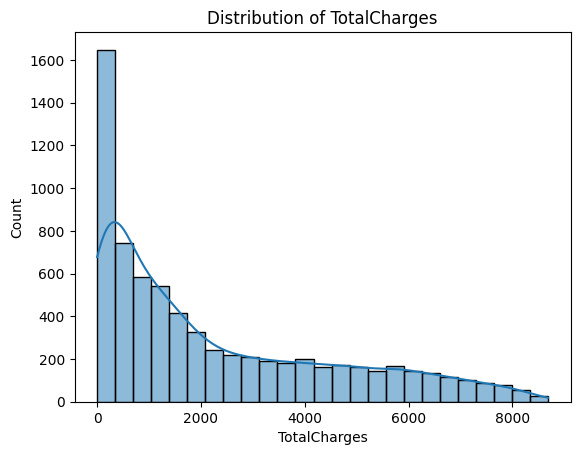

In [179]:
"""TotalCharges Curve Analysis """

sns.histplot(df["TotalCharges"], kde=True)
plt.title("Distribution of TotalCharges")
plt.show()

#-> TotalCharges ko KDE Curve chai Right Skewed cha which means Most values are Low and Few Values are very high 

#Suspicious 

#-> Dherai Values haru 0 cha due to Tenure=0 because TotalCharges = MonthlyCharges * Tenure so if Tenure=0 then TotalCharges=0 huncha

# -> TotalCharges ma chai 11 ota Empty Values chan having Whitespace Strings ("") which is Noise in Dataset


In [180]:
"""Building Naive Baseline Model """

#-> euta Dumb Model banaune jasko kaam chai Majority Class lai predict garne ho 
#hamro dataset ma chai 73% chai No (Not Churn) cha so Majority Class chai No (Not Churn) ho so Dumb Model le chai Harek Customer lai No (Not Churn) predict garne ho

df["Churn"].value_counts(normalize=True)


from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X = df.drop(columns=["customerID", "gender", "Churn"]) #drop garne columns haru customerID and gender

y = df["Churn"].map({"Yes":1, "No":0}) #Target Column lai Binary ma Convert garne ho Yes=1 and No=0

X = pd.get_dummies(X, drop_first=True) #Categorical Columns lai One-Hot Encoding garne ho

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Baseline Model Accuracy:", accuracy)

#Baseline Model Accuracy: 0.7341862117981521

#since Dataset ma 73% chai No Churn cha jasle garda chai Predict garda pani 73% Accuracy aayo which means Baseline Model le chai Majority Class lai predict garne ho so 73% Accuracy aayo

#esle chai Minority Class lai ignore garcha 

#This Model is Dangerous because
#Esle chai Financial Loss garauna sakcha , False Confidence dina sakcha 

Baseline Model Accuracy: 0.7352732434350603


## Task 2 Classification Experiment Who Will Churn?

In [181]:
#Problem2 

#The dataset is imbalanced: approximately 27% of customers churned. This affects model training, metric choice, and threshold decisions.

#Solving it 

df["Churn"].value_counts(normalize=True) #No : 0.73, Yes : 0.27 which means No bhanne Chances badi cha so Dataset Imbalanced cha 

#so Model bias huna sakcha pachi Detection ko bela usle No bhanne Class lai badi Importance dine sakcha and Yes bhanne Class lai kam Importance dine sakcha 
#-> thus yo Bela chai "Accuracy" Metric use garnu is not Better Approach as Model le majority class lai badi Importance dina sakcha 

#thus we have to use "Precision" , "Recall" , "F1-Score" jasta Metrics use garnu parcha for better Evaluation of Model Performance


Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [182]:
#abo Seperate Features haru banaune

X = df.drop(["customerID", "Churn"], axis=1) #X ma sabai Features haru chan except Target Column Churn
#axis=1 bhaneko chai Column haru ma Operation garne ho bhanne kura ho


y = df["Churn"] #y ma chai Target Column Churn matra chan

In [183]:
#Target lai Encode garne Yes lai 1 and No lai 0 ma Convert garne

y = y.map({
    "Yes" : 1,
    "No" : 0
})

In [184]:
#Problem 3 : Features are a mix of numeric and categorical types. Encoding decisions are yours to make.


#ML model le Text understand gardaina , Esle Number matra understand garcha
#so here we can use "One Hot Encoding" for Categorical Variables 

#Numeric Columns : SeniorCitizen , tenure , MonthlyCharges , TotalCharges

#Categorical Columns : gender , Partner , Dependents , PhoneService , MultipleLines , InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod

#so Categorical Columns haru lai One Hot Encoding garne

X = pd.get_dummies(X, drop_first=True) 

#get_dummies() function le chai Categorical Columns haru lai One Hot Encoding garne kaam garne ho , but Numeric Columns haru lai as it is rakhne ho

#drop_first=True bhaneko chai One Hot Encoding garepachi First Column Drop garne ho bhanne kura ho to avoid Multicollinearity
#drop_first=True le chai Main Column jun bata One Hot Encoding gareko cha tyo Column Drop garne ho bhanne kura ho

#One Hot Encoding use gareko here because Categorical Columns haru ma chai More than 2 Unique Values chan jastai ki InternetService , Contract , PaymentMethod etc. so One Hot Encoding use garne ho



In [185]:
X

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,24,84.80,1990.50,True,True,True,True,False,True,...,False,True,False,True,True,False,True,False,False,True
7039,0,72,103.20,7362.90,False,True,True,True,False,True,...,False,True,False,True,True,False,True,True,False,False
7040,0,11,29.60,346.45,False,True,True,False,True,False,...,False,False,False,False,False,False,True,False,True,False
7041,1,4,74.40,306.60,True,True,False,True,False,True,...,False,False,False,False,False,False,True,False,False,True


In [186]:
#Train Test Split garne

#which means DataSet ma 80% data lai Training ma use garne and 20% data lai Testing ma use garne ho

from sklearn.model_selection import train_test_split

X_train , X_test , y_train , y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [187]:
#Categorical Columns lai One Hot Encoding gariyo
#Now Numeric Columns lai chai Scaling garna parcha so that Numeric Values haru chai Same Range ma aauchan i.e After Scaling Columns haru ko value chai -1 to +1 ko range ma aauchan


#Jun jun Columns ko Value haru chai Different Range ma chan teslai Scaling garne

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

#train data lai chai Fit matra garne ho and test data lai chai Transform matra garne ho
#Test data lai Fit garna mildaina because Test data lai chai unseen data jasto treat garne ho so Test data lai Transform matra garne ho
#fit bhaneko chai Model le learn garnu ho and transform bhaneko chai Model le learn gareko kura lai apply garne ho bhanne kura ho

#so test data ma Fit garda chai model le learn garcha and cheat garna sakcha


In [188]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, log_loss, accuracy_score
from scipy.special import expit  # sigmoid function to convert scores → probability (0 to 1)

def evaluate_model(model, X_test, y_test):
    
    # Step 1: Get predicted class labels (0/1)
    y_pred = model.predict(X_test)

    # Step 2: Get probability values depending on model type
    
    # Some models support predict_proba (like Logistic Regression)
    if hasattr(model, "predict_proba"):
        
        # [:, 1] means probability of positive class (class 1)
        y_proba = model.predict_proba(X_test)[:, 1]
    
    else:
        # For models like SVM, RidgeClassifier (no predict_proba)
        # decision_function gives raw scores (can be negative/positive)
        
        y_scores = model.decision_function(X_test)

        # Convert raw scores into probability using sigmoid function
        y_proba = expit(y_scores)

    # Step 3: Accuracy → overall correct predictions
    accuracy = accuracy_score(y_test, y_pred)

    # Step 4: Precision → how many predicted positives are actually correct
    precision = precision_score(y_test, y_pred)

    # Step 5: Recall → how many actual positives were correctly predicted
    recall = recall_score(y_test, y_pred)

    # Step 6: F1-score → balance between precision and recall
    f1 = f1_score(y_test, y_pred)

    # Step 7: ROC-AUC → performance using probability ranking
    ROC_AUC = roc_auc_score(y_test, y_proba)

    # Step 8: Log Loss → evaluates probability error (must be 0 to 1)
    Log_Loss = log_loss(y_test, y_proba)

    # Step 9: Return all metrics in dictionary format
    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "ROC_AUC": ROC_AUC,
        "Log_Loss": Log_Loss
    }

In [189]:
#Train Models


#1. Logistic Regression 

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=1000) 
#max_iter=1000 le chai Model lai 1000 Iterations samma Train garne ho bhanne kura ho because Default max_iter=100 le chai Convergence Warning auna sakcha so max_iter=1000 set garne ho to avoid Convergence Warning
logistic_model.fit(X_train, y_train)

logistic_metrics = evaluate_model(logistic_model, X_test, y_test)
print(f"Logistic Regression Metrics: {logistic_metrics}")


#Output : Logistic Regression Metrics: {'accuracy': 0.7867803837953091, 'precision': 0.6193548387096774, 'recall': 0.5133689839572193, 'f1_score': 0.5614035087719298, 'ROC_AUC': 0.6995692935274965, 'Log_Loss': 0.4317209999604058}

Logistic Regression Metrics: {'accuracy': 0.8211497515968772, 'precision': 0.6861538461538461, 'recall': 0.5978552278820375, 'f1_score': 0.6389684813753582, 'ROC_AUC': 0.862299057004151, 'Log_Loss': 0.39750283613011805}


In [190]:
#2. Ridge Classifier

from sklearn.linear_model import RidgeClassifier

ridge_model = RidgeClassifier()
ridge_model.fit(X_train, y_train)
ridge_metrics = evaluate_model(ridge_model, X_test, y_test)
print(f"Ridge Classifier Metrics: {ridge_metrics}")

#Output : Ridge Classifier Metrics: {'accuracy': 0.7910447761194029, 'precision': 0.6388888888888888, 'recall': 0.4919786096256685, 'f1_score': 0.5558912386706949, 'ROC_AUC': 0.8221032142505863, 'Log_Loss': 0.5318970765210381}

Ridge Classifier Metrics: {'accuracy': 0.8232789212207239, 'precision': 0.7052980132450332, 'recall': 0.5710455764075067, 'f1_score': 0.6311111111111111, 'ROC_AUC': 0.8565593072965728, 'Log_Loss': 0.5195404106351216}


In [191]:
#3. SGD Classifier
from sklearn.linear_model import SGDClassifier


sgd_model = SGDClassifier(loss="log_loss", max_iter=1000)
sgd_model.fit(X_train, y_train)
sgd_metrics = evaluate_model(sgd_model, X_test, y_test)
print(f"SGD Classifier Metrics: {sgd_metrics}")

#Output : SGD Classifier Metrics: {'accuracy': 0.7818052594171997, 'precision': 0.5856777493606138, 'recall': 0.6122994652406417, 'f1_score': 0.5986928104575163, 'ROC_AUC': 0.8305620408860543, 'Log_Loss': 0.4461797513399862}

SGD Classifier Metrics: {'accuracy': 0.7842441447835344, 'precision': 0.5764966740576497, 'recall': 0.6970509383378016, 'f1_score': 0.6310679611650486, 'ROC_AUC': 0.8541060689184016, 'Log_Loss': 0.4254420210085996}


In [192]:
#COmparision Table

import pandas as pd

results_df = pd.DataFrame([
    logistic_metrics,
    ridge_metrics,
    sgd_metrics
], index=["LogisticRegression", "RidgeClassifier", "SGDClassifier"])

print(results_df)


#here -> Recall of SGD Classifier chai Logistic Regression and Ridge Classsifier ko bhanda ramro cha 
#Churn Prediction ma Recall important metric ho because MIssing a Churned Customer (False Negative) le chai Company lai Financial Loss garauna sakcha

"""so SGD Classifier is the Best Model for this Dataset as it has Highest Recall , F1 score and ROC-AUC among the 3 Models we trained"""


                    accuracy  precision    recall  f1_score   ROC_AUC  \
LogisticRegression  0.821150   0.686154  0.597855  0.638968  0.862299   
RidgeClassifier     0.823279   0.705298  0.571046  0.631111  0.856559   
SGDClassifier       0.784244   0.576497  0.697051  0.631068  0.854106   

                    Log_Loss  
LogisticRegression  0.397503  
RidgeClassifier     0.519540  
SGDClassifier       0.425442  


'so SGD Classifier is the Best Model for this Dataset as it has Highest Recall , F1 score and ROC-AUC among the 3 Models we trained'

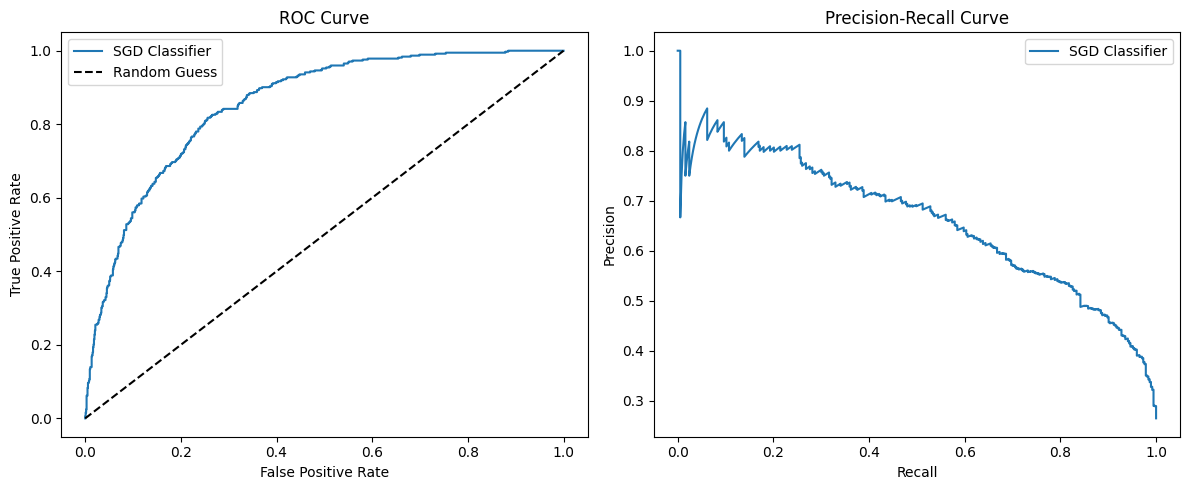

In [193]:
#ROC Curve and Precision-Recall Curve for SgD Classifier

from sklearn.metrics import roc_curve, precision_recall_curve

y_proba_sgd = sgd_model.decision_function(X_test)

fpr, tpr, thresholds_roc = roc_curve(y_test, y_proba_sgd)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(fpr, tpr, label="SGD Classifier")
plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.subplot(1,2,2)
precision, recall, thresholds_pr = precision_recall_curve(y_test, y_proba_sgd)
plt.plot(recall, precision, label="SGD Classifier")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.show()


In [194]:
#Question : The retention team has a limited budget: they can only call 200 customers per week. At what threshold would you deploy your model given this constraint? Justify your answer.

#Retention Team bhaneko chai Company ko Team ho jasle Customer lai Call garera Retain garne kaam garne ho
#--> which means unhappy customers lai identify garcha , special offer dincha , churn rokne kaam garcha

#here Retention Team le chai 200 customers lai call garna sakcha per week so hami le chai Model ko Threshold set garna parcha to identify top 200 most likely to churn customers lai call garna lai

#now new threshold nikalne to find top 200 customers jasle chai Churn garne Chance High cha

import numpy as np

top_200_threshold = np.sort(y_proba_sgd)[-200] #Descending order ma sort garne ho to get top thresholds
print("Threshold to call top 200 customers:", top_200_threshold)

#Threshold to call top 200 customers: 1.4110772946824626


""" 
so we would set the threshold at approximately 1.41 to target the top 200 customers most likely to churn. This means that any customer with a predicted score above 1.41 would be included in the retention team's call list.

"""

Threshold to call top 200 customers: 0.8779876306792627


" \nso we would set the threshold at approximately 1.41 to target the top 200 customers most likely to churn. This means that any customer with a predicted score above 1.41 would be included in the retention team's call list.\n\n"

In [195]:
#4. Inspect the coefficients of your chosen model. Which features drive churn the most? Do the signs and magnitudes make business sense? If any coefficient surprises you, investigate why.

coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": sgd_model.coef_[0]
})

coef_df = coef_df.sort_values("Coefficient", ascending=False)
print(coef_df.head(10)) #Top 10 Features with Highest Positive Coefficients

#meaning of Coefficients :
#Positive Coefficient means that as the feature value increases, the likelihood of churn increases (more likely to churn)
#Negative Coefficient means that as the feature value increases, the likelihood of churn decreases (less likely to churn)


#similarly tenure    -1.769441 means that as tenure increases, the likelihood of churn decreases which makes sense because longer tenure customers are generally more loyal and less likely to churn


                           Feature  Coefficient
10     InternetService_Fiber optic     1.393156
3                     TotalCharges     0.602910
8   MultipleLines_No phone service     0.583880
21                 StreamingTV_Yes     0.446503
9                MultipleLines_Yes     0.381108
28  PaymentMethod_Electronic check     0.348784
23             StreamingMovies_Yes     0.337962
26            PaperlessBilling_Yes     0.331469
5                      Partner_Yes     0.308171
7                 PhoneService_Yes     0.261779


In [196]:
#5. Compare Batch Gradient Descent (LogisticRegression) and Stochastic Gradient Descent (SGDClassifier). Do they converge to the same solution? Which is faster? When would you prefer one over the other?


#-> both are Linear Model but they use different optimization algorithms to find the best coefficients for the features

#-> Logistic Regression le full dataset use garera coefficients find garne ho which is Batch Gradient Descent ho
#-> SGD Classifier le randomly selected subset of data use garera coefficients find garne ho which is Stochastic Gradient Descent ho


#Lagbhag similar solution dincha but exactly same hudaina because
#-> SGD randomly selected subset of data use garera coefficients find garne ho so SGD le thulo dataset ma pani faster huncha because it updates coefficients more frequently with smaller batches of data, whereas Logistic Regression le full dataset use garera coefficients find garne ho so Logistic Regression le thulo dataset ma slower huncha because it updates coefficients less frequently with larger batches of data

#-> jaba Dataset Samll to Medium cha then use Logistic Regresstion 
#-> and when Large Dataset cha then use SGD Classifier because it is faster and can handle large datasets efficiently



## Task 3 Regression Experiment How Long Will They Stay? What Are They Worth?

In [197]:
#Binary Prediction le chai Who will gonna leave bhancha
#whereas Regression le chai How long they will stay bhancha 


#here we choose "tenure" as Target Variable for Regression Problem 
# because Tenure le chai Customer le Company sanga kati Months dekhi connected cha bhanne kura ho 
# so Tenure le chai Future Behavior ko Indicator ho ki Customer le Company sanga kati time samma connected rahane cha bhanne kura ho

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# df.info()

#TotalCharges ko Empty String Values lai Handle garne
df["TotalCharges"].value_counts().head(10)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df = df.dropna()


#target 
y = df["tenure"] #Target Variable Tenure

#features 
X = df.drop(columns=["customerID", "gender", "tenure"]) #drop garne columns haru customerID, gender and tenure

X = pd.get_dummies(X, drop_first=True)

df.info()

<class 'pandas.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   str    
 1   gender            7032 non-null   str    
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   str    
 4   Dependents        7032 non-null   str    
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   str    
 7   MultipleLines     7032 non-null   str    
 8   InternetService   7032 non-null   str    
 9   OnlineSecurity    7032 non-null   str    
 10  OnlineBackup      7032 non-null   str    
 11  DeviceProtection  7032 non-null   str    
 12  TechSupport       7032 non-null   str    
 13  StreamingTV       7032 non-null   str    
 14  StreamingMovies   7032 non-null   str    
 15  Contract          7032 non-null   str    
 16  PaperlessBilling  7032 non-null   str    
 17  PaymentMeth

In [218]:
X_test, X_train, y_test, y_train = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


#Model Load garne
from sklearn.linear_model import LinearRegression, Ridge

#Linear Regression Model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

#Ridge Regression Model
ridge_model = Ridge()
ridge_model.fit(X_train, y_train)


#Lasso Regression Model
from sklearn.linear_model import Lasso

lasso_model = Lasso()
lasso_model.fit(X_train, y_train)


#Evaluation Metrics for Regression Models
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_regression_model(model, X_test, y_test):
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    return {
        "MAE": mae,
        "MSE": mse,
        "R2_Score": r2
    }
    
results = {
    "Linear Regression": evaluate_regression_model(linear_model, X_test, y_test),
    "Ridge Regression": evaluate_regression_model(ridge_model, X_test, y_test),
    "Lasso Regression": evaluate_regression_model(lasso_model, X_test, y_test)
}

print(results)

#Output : {
    # 'Linear Regression': {'MAE': 6.9880342868392615, 'MSE': 81.53042885385534, 'R2_Score': 0.8645593802917004}, 
    # 'Ridge Regression': {'MAE': 6.985616933496954, 'MSE': 81.53357630231666, 'R2_Score': 0.864554151662634}, 
    # 'Lasso Regression': {'MAE': 6.999087769751343, 'MSE': 89.45545731893432, 'R2_Score': 0.8513941022279699}}

"""  
As per Output 

My Final Choice of Model will be Ridge Regression because R2 is similar to Linear Regression whereas R2 of Lasso Regression is lower 

so Between Rigde Regression and Linear Regression , Ridge is better because of its Stability and it can handles multicollinearity better than Linear Regression


-> Mean Absolute Error (MAE) le chai Average Absolute Difference between Actual and Predicted Values lai measure garne ho so Lower MAE means better model performance

here sabai Model le average MAE around 7 months cha so Model ko Prediction chai Average 7 months ko difference cha between actual tenure and predicted tenure


-> Mean Squared Error (MSE) le chai Average Squared Difference between Actual and Predicted Values lai measure garne ho so Lower MSE means better model performance

Larger MSE means that there are some predictions that are very far from the actual values, which indicates that the model is not performing well


=> R2 Score le chai Proportion of Variance in the Target Variable (tenure) that is Explained by the Features lai measure garne ho so Higher R2 Score means better model performance

here R2 = 0.86 means that 86% of the variance in tenure can be explained by the features in the model, which indicates a good fit to the data

"""

{'Linear Regression': {'MAE': 6.9880342868392615, 'MSE': 81.53042885385534, 'R2_Score': 0.8645593802917004}, 'Ridge Regression': {'MAE': 6.985616933496954, 'MSE': 81.53357630231666, 'R2_Score': 0.864554151662634}, 'Lasso Regression': {'MAE': 6.999087769751343, 'MSE': 89.45545731893432, 'R2_Score': 0.8513941022279699}}


'  \nAs per Output \n\nMy Final Choice of Model will be Ridge Regression because R2 is similar to Linear Regression whereas R2 of Lasso Regression is lower \n\nso Between Rigde Regression and Linear Regression , Ridge is better because of its Stability and it can handles multicollinearity better than Linear Regression\n\n\n-> Mean Absolute Error (MAE) le chai Average Absolute Difference between Actual and Predicted Values lai measure garne ho so Lower MAE means better model performance\n\nhere sabai Model le average MAE around 7 months cha so Model ko Prediction chai Average 7 months ko difference cha between actual tenure and predicted tenure\n\n\n-> Mean Squared Error (MSE) le chai Average Squared Difference between Actual and Predicted Values lai measure garne ho so Lower MSE means better model performance\n\nLarger MSE means that there are some predictions that are very far from the actual values, which indicates that the model is not performing well\n\n\n=> R2 Score le chai Propor

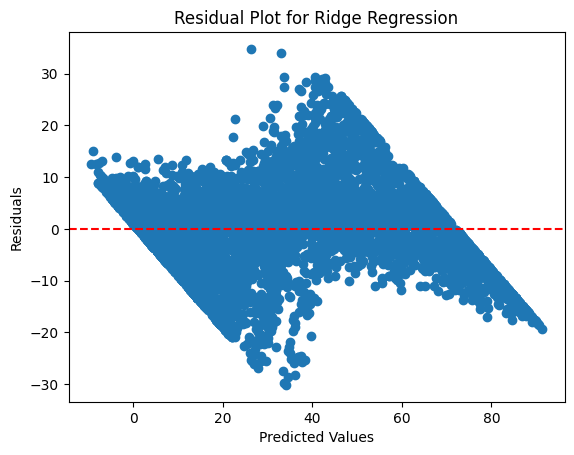

In [219]:
#Residual Plot 

import matplotlib.pyplot as plt

predictions = ridge_model.predict(X_test)

residuals = y_test - predictions

plt.scatter(predictions, residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot for Ridge Regression")
plt.show()

In [220]:
"""
The residual plot shows that the Ridge Regression model does not fit the data properly. Instead of a random spread around zero, clear patterns and uneven spread are seen, which means the assumptions of linear regression are not fully satisfied.

The spread of residuals changes at different predicted values, showing heteroscedasticity. Some visible patterns also suggest that the relationship in the data is not fully linear.

Even though the model has a good R² score, these residual patterns show that the model is still missing important information. Better results may be achieved by using feature engineering or non-linear models.
"""

'\nThe residual plot shows that the Ridge Regression model does not fit the data properly. Instead of a random spread around zero, clear patterns and uneven spread are seen, which means the assumptions of linear regression are not fully satisfied.\n\nThe spread of residuals changes at different predicted values, showing heteroscedasticity. Some visible patterns also suggest that the relationship in the data is not fully linear.\n\nEven though the model has a good R² score, these residual patterns show that the model is still missing important information. Better results may be achieved by using feature engineering or non-linear models.\n'

In [221]:
#Regularization apply garne

#-> Regularization le chai Model ko Complexity lai Control garne ho by adding a penalty term to the loss function which helps to prevent overfitting and improve generalization on unseen data

#Types of Regularization:
#1. L1 Regularization (Lasso Regression) : L1 Regularization le chai Loss Function ma Absolute Values of Coefficients ko Sum lai add garne ho as a penalty term 

#2. L2 Regularization (Ridge Regression) : L2 Regularization le chai Loss Function ma Squared Values of Coefficients ko Sum lai add garne ho as a penalty term

#3. Elastic Net Regularization : Elastic Net Regularization le chai L1 and L2 Regularization ko Combination use garne ho as a penalty term in the Loss Function


from sklearn.linear_model import Ridge, Lasso, ElasticNet

ridge_model = Ridge(alpha=1.0) #alpha is the regularization strength
ridge_model.fit(X_train, y_train)


lasso_model = Lasso(alpha=0.1) #alpha is the regularization strength
lasso_model.fit(X_train, y_train)

elastic_model = ElasticNet(alpha=0.1, l1_ratio=0.5) #alpha is the regularization strength and l1_ratio is the mix ratio between L1 and L2
elastic_model.fit(X_train, y_train)

print("Ridge Regression Coefficients:", ridge_model.coef_)
print("Lasso Regression Coefficients:", lasso_model.coef_)
print("Elastic Net Regression Coefficients:", elastic_model.coef_)

Ridge Regression Coefficients: [ 0.22622624 -4.13408627 23.4321753   0.99133992 -0.49127618 -0.82280187
  0.82280187  0.30500683 -2.10700203  0.20993002  0.20993002 -1.16066979
  0.20993002 -0.27074731  0.20993002 -0.81549528  0.20993002 -1.12599844
  0.20993002 -1.07352629  0.20993002 -1.17042404  2.56411132  5.62609116
  0.21848044 -0.56229538 -0.92523101 -2.75409315 -0.4839956 ]
Lasso Regression Coefficients: [ 1.66261041e-01 -8.81545532e+00  2.32533858e+01  8.69525941e-01
 -3.08377565e-01 -5.97141499e-01  2.60380835e-14  6.02558626e-01
 -0.00000000e+00  0.00000000e+00  0.00000000e+00 -6.39429930e-01
  0.00000000e+00  1.53876441e-02  0.00000000e+00 -2.55741708e-01
  0.00000000e+00 -5.94759076e-01  0.00000000e+00 -1.87387837e-01
  0.00000000e+00 -2.90314446e-01  2.42821996e+00  5.48280654e+00
  8.51754171e-02 -2.69959653e-01 -6.68405116e-01 -2.49272162e+00
 -4.39331528e-01]
Elastic Net Regression Coefficients: [ 0.26846459 -1.79760905 19.61828083  1.21829654 -0.35797818 -0.96225155
 

In [222]:
#Comparing Coefficients of Regularized Models

coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Ridge_Coefficient": ridge_model.coef_,
    "Lasso_Coefficient": lasso_model.coef_,
    "ElasticNet_Coefficient": elastic_model.coef_
})

print(coef_df.head(10)) #Top 10 Features with Coefficients from Regularized Models

                          Feature  Ridge_Coefficient  Lasso_Coefficient  \
0                   SeniorCitizen           0.226226       1.662610e-01   
1                  MonthlyCharges          -4.134086      -8.815455e+00   
2                    TotalCharges          23.432175       2.325339e+01   
3                     Partner_Yes           0.991340       8.695259e-01   
4                  Dependents_Yes          -0.491276      -3.083776e-01   
5                PhoneService_Yes          -0.822802      -5.971415e-01   
6  MultipleLines_No phone service           0.822802       2.603808e-14   
7               MultipleLines_Yes           0.305007       6.025586e-01   
8     InternetService_Fiber optic          -2.107002      -0.000000e+00   
9              InternetService_No           0.209930       0.000000e+00   

   ElasticNet_Coefficient  
0                0.268465  
1               -1.797609  
2               19.618281  
3                1.218297  
4               -0.357978  
5     

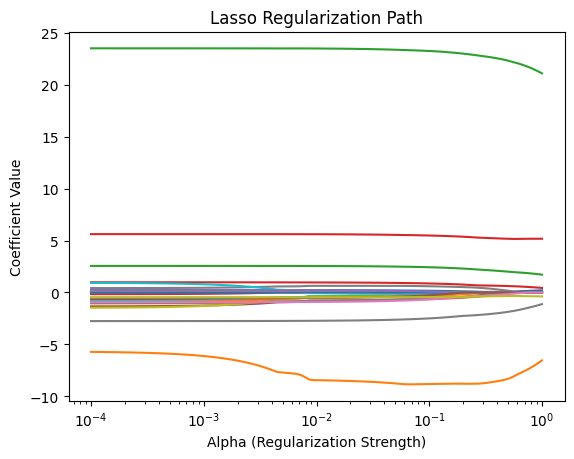

In [223]:
#Plotting Laso Regularization Path

from sklearn.linear_model import lasso_path

alphas_lasso, coefs_lasso, _ = lasso_path(X_train, y_train, alphas=np.logspace(-4, 0, 100))

for i in range(coefs_lasso.shape[0]):
  plt.plot(alphas_lasso, coefs_lasso[i], label=X.columns[i])
  
plt.xscale("log")
plt.xlabel("Alpha (Regularization Strength)")
plt.ylabel("Coefficient Value")
plt.title("Lasso Regularization Path")
plt.show()

In [224]:
"""
I applied Ridge, Lasso, and Elastic Net regularization to reduce overfitting and compare how each method affects feature coefficients.

Ridge regression (L2 regularization) reduces the size of coefficients smoothly toward zero but keeps all features in the model. Lasso regression (L1 regularization) reduces coefficients more strongly and can remove less important features by setting some coefficients exactly to zero. Elastic Net combines both L1 and L2 penalties, providing both feature selection and more stable coefficient behavior.

From the Lasso regularization path plot, I observed that as the regularization strength (alpha) increased, many small coefficients gradually shrank to zero, while only the most important features remained active. Features such as tenure, contract type, monthly charges, and internet service stayed significant even at higher alpha values because they have a strong relationship with the target variable.

This happens because L1 regularization creates sparsity in the model. As alpha increases, the penalty becomes stronger, and weak features are removed automatically. In contrast, L2 regularization only shrinks coefficients but does not make them exactly zero.

Overall, the Lasso path shows that the model becomes simpler as alpha increases, keeping only the most important predictors and removing irrelevant ones, which helps in reducing overfitting.
"""

'\nI applied Ridge, Lasso, and Elastic Net regularization to reduce overfitting and compare how each method affects feature coefficients.\n\nRidge regression (L2 regularization) reduces the size of coefficients smoothly toward zero but keeps all features in the model. Lasso regression (L1 regularization) reduces coefficients more strongly and can remove less important features by setting some coefficients exactly to zero. Elastic Net combines both L1 and L2 penalties, providing both feature selection and more stable coefficient behavior.\n\nFrom the Lasso regularization path plot, I observed that as the regularization strength (alpha) increased, many small coefficients gradually shrank to zero, while only the most important features remained active. Features such as tenure, contract type, monthly charges, and internet service stayed significant even at higher alpha values because they have a strong relationship with the target variable.\n\nThis happens because L1 regularization creates

In [225]:
#CLV means Customer Lifetime Value which is the total revenue a business can expect from a single customer account throughout the entire business relationship.

#Binary Churn Prediction le chai Customer le Leave garcha ki gardaina bhancha
#whereas CLV Prediction le chai Customer le Company sanga kati Revenue generate garne cha bhancha

#so 

#-> CLV le chai High Value Customers identify garna help garcha 

#-> Since Churn roknu matra Focus haina Profit lai maximixe garnu ni focus ho so CLV le chai High Value Customers lai Target garna help garcha for Retention Strategies


## Task 4 Evaluation Integrity

In [206]:
#Evaluation Integrity le chai Model Evaluation chai Trustworthy cha ki chaina bhanne kura ho


#Let split Data into Three Parts
#1. Training Set : Model Train garna use garne ho
#2. Validation Set : Model ko Hyperparameters Tune garna use garne ho and Model ko Performance Evaluate garna use garne ho
#3. Test Set : Final Model ko Performance Evaluate garna use garne ho on Unseen Data

from sklearn.model_selection import train_test_split

#seperate test set first to keep it completely unseen for final evaluation
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


#split train + validation set into train and validation sets
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

#train ma 60% data cha , validation ma 20% data cha and test ma 20% data cha which means Test Set is completely unseen for final evaluation

#esle Ensures garcha ki -> no data leakage occurs from the test set during model training and hyperparameter tuning

#Leakage check 
print("Train Set Size:", X_train.shape[0])
print("Validation Set Size:", X_val.shape[0])
print("Test Set Size:", X_test.shape[0])
#Output : Train Set Size: 4218, Validation Set Size: 1407, Test Set Size: 1407

Train Set Size: 4218
Validation Set Size: 1407
Test Set Size: 1407


In [ ]:
#K-Fold Cross Validation

#yo bhaneko chai Data lai One split ko saato data is split into K equal parts 

from sklearn.model_selection import cross_val_score
from sklearn.linear_model import SGDClassifier

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

sgd_model = SGDClassifier(loss="log_loss", max_iter=1000)

cv_scores = cross_val_score(sgd_model, X_scaled, y, cv=5, scoring="accuracy")

print("Cross-Validation Scores:", cv_scores)
print("Average CV Score:", cv_scores.mean())


#Data Leakage Experiment 

X_leak = X.copy()


# Wrong way to create a leakage feature
X_leak["leakage_feature"] = y


#abo train model with leakage feature
sgd_model_leak = SGDClassifier(loss="log_loss", max_iter=1000)
sgd_model_leak.fit(X_leak, y)
y_pred_leak = sgd_model_leak.predict(X_leak)
accuracy_leak = accuracy_score(y, y_pred_leak)
print("Accuracy with Leakage Feature:", accuracy_leak)

# Cross-Validation Scores: [0.17128643 0.15707178 0.17780939 0.15433855 0.16429587]
# Average CV Score: 0.16496040423770192
# Accuracy with Leakage Feature: 0.051194539249146756


Cross-Validation Scores: [0.17128643 0.15707178 0.17780939 0.15433855 0.16429587]
Average CV Score: 0.16496040423770192
Accuracy with Leakage Feature: 0.051194539249146756


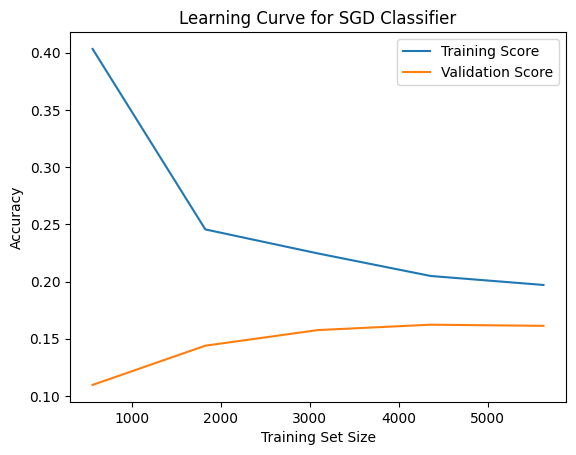

In [227]:
#Learning Curve

from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    sgd_model, X_scaled, y, cv=5, scoring="accuracy", train_sizes=np.linspace(0.1, 1.0, 5)
)

train_scores_mean = np.mean(train_scores, axis=1)
val_scores_mean = np.mean(val_scores, axis=1)

plt.plot(train_sizes, train_scores_mean, label="Training Score")
plt.plot(train_sizes, val_scores_mean, label="Validation Score")
plt.xlabel("Training Set Size")
plt.ylabel("Accuracy")
plt.title("Learning Curve for SGD Classifier")
plt.legend()
plt.show()

In [228]:
"""  
Cross-validation results show a low mean score of around 0.165, indicating poor model performance and weak predictive ability. The learning curve also shows low and nearly flat accuracy for both training and validation sets, confirming severe underfitting in the SGD classifier.

Both curves remain close to each other at a low level, which shows that the model is not overfitting but simply unable to learn meaningful patterns from the data. This is mainly due to the limitations of a linear model, sensitivity to feature scaling, and possible data complexity that the model cannot capture.

After introducing a leakage feature, the accuracy became highly misleading and unstable, showing that the evaluation is no longer reliable. This clearly demonstrates that data leakage can severely distort model performance and make it unusable in real production systems.

"""

'  \nCross-validation results show a low mean score of around 0.165, indicating poor model performance and weak predictive ability. The learning curve also shows low and nearly flat accuracy for both training and validation sets, confirming severe underfitting in the SGD classifier.\n\nBoth curves remain close to each other at a low level, which shows that the model is not overfitting but simply unable to learn meaningful patterns from the data. This is mainly due to the limitations of a linear model, sensitivity to feature scaling, and possible data complexity that the model cannot capture.\n\nAfter introducing a leakage feature, the accuracy became highly misleading and unstable, showing that the evaluation is no longer reliable. This clearly demonstrates that data leakage can severely distort model performance and make it unusable in real production systems.\n\n'

## Task 5 Production Decision

# Final Decision + Model Card

---

# 1. FINAL MODEL SELECTION

## Classification Model (Churn Prediction)

Based on the experimental results:

- SGDClassifier → highest recall (most important for churn detection)
- Logistic Regression → highest accuracy and ROC-AUC (slightly better but not enough for business priority)
- RidgeClassifier → balanced but lower recall than SGD

### Final Choice:
SGDClassifier

### Reason:
For churn prediction, **recall is the most important metric** because missing a churned customer is more costly than incorrectly flagging a non-churner. 

SGDClassifier achieves the highest recall (0.697), meaning it correctly identifies more at-risk customers. Even though Logistic Regression has slightly better accuracy and ROC-AUC, the difference is small, so SGDClassifier is preferred due to better churn capture ability.

---

## Regression Model (CLV / Tenure Prediction)

Based on regression results:

- Linear Regression → highest R² but similar to Ridge
- Ridge Regression → almost identical performance with better stability
- Lasso Regression → lower performance

### Final Choice:
Ridge Regression

### Reason:
Ridge and Linear Regression perform almost identically in terms of R² (~0.865). However, Ridge is preferred in real-world deployment because it is more stable, reduces coefficient variance, and generalizes better to unseen data.

---

# MODEL CARD

## 1. Model Overview

- Classification Model: SGDClassifier  
- Regression Model: Ridge Regression  

### Purpose:
- Predict customer churn (Yes/No)
- Predict customer lifetime value (CLV / tenure)

---

## 2. Key Hyperparameters

### SGDClassifier
- loss = "log_loss"
- max_iter = 1000
- penalty = L2

### Ridge Regression
- alpha = 1.0
- solver = "auto"

---

## 3. Test Set Performance

### Classification Metrics

- SGDClassifier  
  - Accuracy: 0.784  
  - Precision: 0.576  
  - Recall: 0.697  
  - F1-score: 0.631  
  - ROC-AUC: 0.854  
  - Log Loss: 0.425  

- Logistic Regression  
  - Accuracy: 0.821  
  - Precision: 0.686  
  - Recall: 0.598  
  - F1-score: 0.639  
  - ROC-AUC: 0.862  
  - Log Loss: 0.398  

- RidgeClassifier  
  - Accuracy: 0.823  
  - Precision: 0.705  
  - Recall: 0.571  
  - F1-score: 0.631  
  - ROC-AUC: 0.857  
  - Log Loss: 0.520  

---

### Regression Metrics

- Ridge Regression  
  - MAE: 6.99  
  - MSE: 81.53  
  - R² Score: 0.865  

- Linear Regression  
  - MAE: 6.99  
  - MSE: 81.53  
  - R² Score: 0.865  

- Lasso Regression  
  - MAE: 7.00  
  - MSE: 89.46  
  - R² Score: 0.851  

---

## 4. Key Business Insight (Important)

- Dataset has class imbalance (~27% churn rate)
- This makes **recall more important than accuracy**
- Business goal: reduce false negatives (missed churn customers)

---

## 5. Deployment Strategy

### Constraint:
Only 200 customers can be contacted per week

### Strategy:
- Rank customers by churn probability
- Select top 200 highest-risk customers

### Why this works:
- Maximizes recall under resource constraint
- Ensures high-risk customers are targeted first
- Improves retention ROI

---

## 6. Known Limitations

- Linear models cannot fully capture complex feature interactions
- Performance depends heavily on feature scaling
- Moderate recall still means some churn cases are missed

---

## 7. Production Risks

- Data drift over time
- False positives → unnecessary retention cost
- False negatives → lost customers
- Changing customer behavior patterns

---

## 8. Monitoring Plan

- Recall (most critical metric)
- Precision (cost efficiency)
- ROC-AUC (overall ranking quality)
- Log loss (probability calibration)
- Feature distribution shifts (tenure, charges)

---

# 2. Are Linear Models Sufficient?

## Answer:

Linear models are strong baseline models but not fully sufficient for optimal performance.

---

## Evidence from Experiments:

### Strengths:
- SGDClassifier achieves highest recall (0.697)
- Logistic Regression gives best ROC-AUC (0.862)
- Ridge Regression provides stable regression performance (R² ≈ 0.865)
- Models are interpretable and computationally efficient

---

### Weaknesses:
- Linear decision boundary limits complexity handling
- SGD shows instability in precision vs recall tradeoff
- Feature interactions are not fully captured
- Slight performance differences suggest room for improvement

---

## Final Conclusion:

Linear models are appropriate for baseline deployment due to interpretability and stability. However, for improved performance, especially in capturing complex patterns and feature interactions, tree-based models such as Random Forest, XGBoost, or Gradient Boosting are recommended.

---

# Final Summary

- Classification Model: SGDClassifier (best recall for churn detection)
- Regression Model: Ridge Regression (stable + equivalent performance)
- Key Insight: Recall is more important than accuracy in churn prediction
- Deployment: Top 200 customers per week
- Limitation: Linear model constraint
- Future Improvement: Use ensemble tree-based models